<a href="https://colab.research.google.com/github/iwemrn/data_analysis_itmo/blob/main/%D0%9B%D0%A03_%D0%95%D1%80%D0%BE%D1%85%D0%B8%D0%BD%D0%B0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Лабораторная работа №3. DBSCAN.**
ФИО: Ерохина Софья Алексеевна
Файл: Леденцы

**План выполнения работы:**

1. Изучить принципы работы алгоритма DBSCAN и его основные параметры.
2. Обосновать выбор параметров `eps` и `min_samples`.
3. Выполнить кластеризацию методом DBSCAN.
4. Определить количество кластеров и шумовых наблюдений.
5. Оценить качество кластеризации.
6. Визуализировать результаты с использованием PCA.
7. Провести содержательную интерпретацию кластеров и анализ шумовых объектов.
8. Сравнить результаты с предыдущими методами кластеризации.

В файле "леденцы.pdf" дано описание данных по признакам. Продублирую их в текущем файле:
* V1: Я потребляю леденцы, чтобы освежить дыхание
* V2: Я потребляю леденцы, чтобы чувствовать себя увереннее
* V3: Я потребляю леденцы, чтобы освежить полость рта
* V4: Я потребляю леденцы, чтобы избавиться от неприятного вкуса во рту
* V5: Я потребляю леденцы как заменитель других кондитерских изделий
* V6: Я потребляю леденцы, когда мне хочется чего-нибудь сладкого
* V7: Леденцы помогают мне сконцентрироваться
* V8: Я потребляю леденцы, чтобы отвлечься на несколько минут и подумать
* V9: Я потребляю леденцы для того, чтобы облегчить боль в горле
* V10: Я потребляю леденцы для того, чтобы избавиться от заложенности носа
* V11: Я потребляю леденцы для улучшения самочувствия

---

Первично, можно разделить данные признаки на следующие группы: признаки V1-V4 могут говорить о гигиене и свежести, признаки V5 и V6 - "любовь" к сладостям, признаки V7 и V8 говорят о психологическом комфорте, признаки V9 - V11 - облегчение симптомов болезни.


Для работы подключаем библиотеки:

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
%matplotlib inline

plt.style.use('ggplot')

Загружаем файл с исходными данными:

In [ ]:
drive.mount("/content/drive")

df = pd.read_csv("/content/drive/MyDrive/AD_Python/Леденцы.dat", sep=";")

df.head()

Mounted at /content/drive


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


Далее - посмотрим на структуру данных

In [ ]:
print("Размер таблицы:", df.shape)

print("\nТипы данных:")
print(df.dtypes)

print("\nПропущенные значения:")
print(df.isnull().sum())

print("\nОписательная статистика:")
display(df.describe())

Размер таблицы: (338, 11)

Типы данных:
V1     int64
V2     int64
V3     int64
V4     int64
V5     int64
V6     int64
V7     int64
V8     int64
V9     int64
V10    int64
V11    int64
dtype: object

Пропущенные значения:
V1     0
V2     0
V3     0
V4     0
V5     0
V6     0
V7     0
V8     0
V9     0
V10    0
V11    0
dtype: int64

Описательная статистика:


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
count,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000
mean,3.544379,3.526627,3.517751,3.411243,3.207101,3.204142,3.254438,3.289941,3.603550,3.550296,3.565089
std,0.955748,0.956410,0.990150,0.992311,0.867314,0.869725,0.844107,0.821784,0.969682,0.927082,0.942042
min,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000
25%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
50%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
75%,5.000000,5.000000,5.000000,4.000000,3.000000,3.000000,3.000000,3.000000,5.000000,5.000000,5.000000
max,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000


При просмотре видим, что шакала оценок варьируется от 2 до 5,количество данных - 338, а среднее и отклонение находятся в диапозоне от 3,20 до 3,60 и от 0,82 до 0,99, соответственно. Это позволяет предположить, что ни один из признаков не будет существенно доминировать при рассчёте расстояний.
Но, для дальнейшего определения наличия или отсутствия однородности респондентов следует исследовать далее.

Говоря об стандартизации - как было помечено ранее, данные варьируются от 2 до 5, и измерены по одной шкале, следовательно, в рамках анализа можно использовать исходные данные без стандартизации

Далее - создадим матрицу признаков для дальнейшей кластеризации

In [ ]:

# Каждая строка — респондент.
# Каждый столбец — оценка одного из 11 высказываний.

features = [f'V{i}' for i in range(1, 12)]

X = df[features].copy()

print("Размер матрицы:", X.shape)
display(X.head())


Размер матрицы: (338, 11)


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


Перейдём к подбору метрик и выбору метода вычисления расстояний между наблюдениями.

DBSCAN (Density-Based Spatial Clustering of Applications with Noise) — алгоритм кластеризации, основанный на поиске областей повышенной плотности наблюдений.

В отличие от методов иерархической кластеризации и K-means, DBSCAN не требует предварительного задания количества кластеров. Алгоритм самостоятельно формирует группы на основании близости и плотности объектов.

Основными параметрами DBSCAN являются:

- `eps` — радиус окрестности, в пределах которой объекты считаются соседями.
- `min_samples` — минимальное количество наблюдений в окрестности, необходимое для признания точки ядерной, включая саму точку.
- `metric` — способ вычисления расстояний между наблюдениями.

В результате работы алгоритма объекты могут быть отнесены к ядерным, граничным или шумовым точкам. Шумовые наблюдения получают метку `-1` и не включаются ни в один из выделенных кластеров.

Для получения содержательно интерпретируемого результата необходимо обосновать выбор параметров `eps` и `min_samples`.

### Предварительный выбор min_samples

Для выбора параметра `min_samples` были рассмотрены эмпирические рекомендации, учитывающие размерность пространства признаков и количество наблюдений.

Поскольку набор данных содержит 338 респондентов и 11 признаков, были выбраны следующие значения:

- `min_samples = 6` — округлённое значение натурального логарифма количества наблюдений;
- `min_samples = 12` — значение, соответствующее числу признаков, увеличенному на единицу;
- `min_samples = 22` — значение, в два раза превышающее число признаков.

Указанные значения используются для предварительного анализа. Окончательный выбор будет выполнен после изучения расстояний до ближайших соседей и сравнения результатов кластеризации.

Рассмотрим график расстояний до k-ближайшего соседа для определения метрики `min_samples`

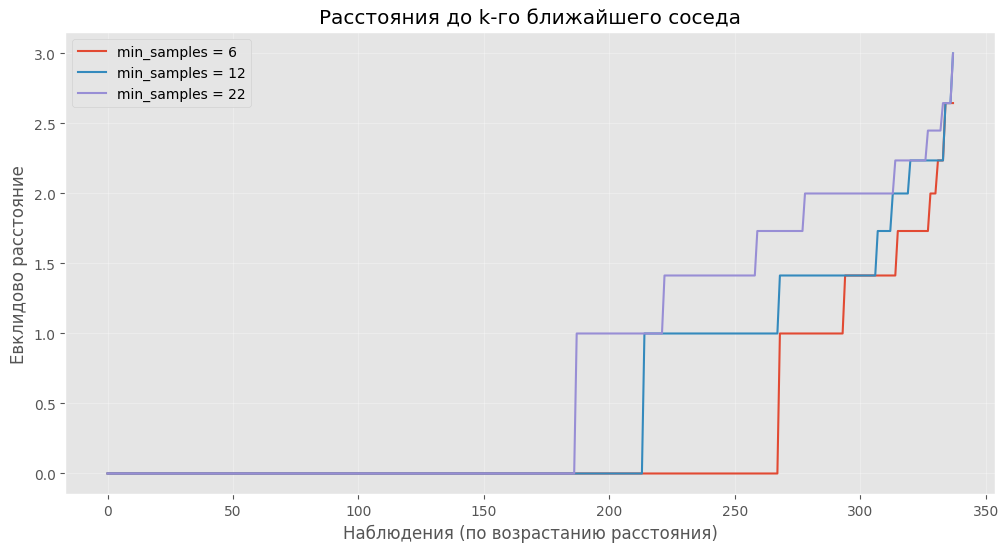

In [ ]:
# Рассматриваем три значения min_samples
min_samples_values = [6, 12, 22]

plt.figure(figsize=(12, 6))

for m in min_samples_values:

    # Поиск ближайших соседей
    neighbors = NearestNeighbors(
        n_neighbors=m,
        metric='euclidean'
    )

    neighbors.fit(X)

    # Расстояния до ближайших соседей
    distances, _ = neighbors.kneighbors(X)

    # Сортируем расстояния до m-го соседа
    k_distances = np.sort(distances[:, -1])

    plt.plot(
        k_distances,
        label=f'min_samples = {m}'
    )

plt.title('Расстояния до k-го ближайшего соседа')
plt.xlabel('Наблюдения (по возрастанию расстояния)')
plt.ylabel('Евклидово расстояние')
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

Все три кривые имеют ступенчатую структуру и достаточно длинный горизонтальный участок на уровне нуля, что связано с особенностью нашего датасета «Леденцы»: некоторые респонденты имеют полностью одинаковые наборы ответов.
Рассмотрим поведение `min_samples` и интерпретируем результаты:
при минимальном количестве наблюдений, равного 6, наблюдается рост примерно после 270-го наблюдения, и имеет самый длинный нулевой участок. При количестве равного 12, рост наблюдается	примерно после 210-го наблюдения. И заключительное количество наблюдений, в два раза большее, чем количестве признаков, имеет рост примерно после 185-го наблюдения.

В качестве рассматриваемой метрики, предположительно, выбор пал на значение `min_samples = 12`, потому как значение соответствует эмпирическому правилу \(D+1\), где \(D=11\) — размерность пространства признаков, и он позволяет проверить, насколько устойчиво алгоритм выделяет плотные области, не устанавливая сразу наиболее жёсткое требование к числу соседей.

На графике для `min_samples=12` наблюдается переход от нулевых расстояний к расстоянию 1, а затем дальнейший рост.

В качестве кандидатов на параметр `eps` рассматриваются значения вблизи характерного перехода от нулевых расстояний к положительным значениям. Окончательный выбор параметров будет выполнен на основании анализа количества кластеров, шумовых наблюдений и устойчивости результатов кластеризации.

In [ ]:

# Проверяем разные сочетания параметров DBSCAN

eps_values = [0.5, 0.9, 1.0, 1.2, 1.5, 2.0]
min_samples_values = [6, 12, 22]

results = []

for m in min_samples_values:
    for eps in eps_values:

        model = DBSCAN(
            eps=eps,
            min_samples=m,
            metric='euclidean'
        )

        labels = model.fit_predict(X)

        # Количество кластеров без шума
        n_clusters = len(set(labels) - {-1})

        # Количество шумовых наблюдений
        n_noise = np.sum(labels == -1)

        results.append({
            'min_samples': m,
            'eps': eps,
            'Кластеров': n_clusters,
            'Шумовых объектов': n_noise,
            'Доля шума (%)': round(
                n_noise / len(X) * 100, 2
            )
        })

results_df = pd.DataFrame(results)

display(results_df)


,min_samples,eps,Кластеров,Шумовых объектов,Доля шума (%)
0,6,0.5,12,70,20.71
1,6,0.9,12,70,20.71
2,6,1.0,9,44,13.02
3,6,1.2,9,44,13.02
4,6,1.5,8,19,5.62
5,6,2.0,3,4,1.18
6,12,0.5,6,124,36.69
7,12,0.9,6,124,36.69
8,12,1.0,6,69,20.41
9,12,1.2,6,69,20.41


Установлено, что при увеличении параметра `min_samples` алгоритм предъявляет более строгие требования к плотности наблюдений. Это приводит к увеличению числа шумовых объектов и может сокращать количество выделяемых кластеров.

Наименьшая доля шума наблюдается, согласно таблице, при `eps=2.0` и `min_samples=6` или 12, и составляет 1,18%.
Но при этом алгоритм выделяет только три кластера. Возможно, часть ранее самостоятельных групп объединяется.
При `eps=1.5` было выделено семь кластеров, а число шумовых объектов составило `29 (8,58%)`. При `eps=2.0` количество кластеров сократилось до трёх, а число шумовых наблюдений — до четырёх `(1,18%)`.

Несмотря на минимальную долю шума при большем радиусе, данный показатель не может использоваться как единственный критерий выбора параметров, поскольку увеличение eps способно приводить к объединению содержательно различных групп.

Проанализируем численность кластеров при `min_samples=12` и `eps = [1.5, 2.0]`.
Группа `-1` говорит о шумах, которые были выявлены DBSCAN'ом

In [ ]:
eps_values = [1.5, 2.0]
min_samples = 12

for eps in eps_values:
    model = DBSCAN(
        eps=eps,
        min_samples=min_samples,
        metric='euclidean'
    )

    labels = model.fit_predict(X)

    print(f'\neps = {eps}, min_samples = {min_samples}')
    print('Количество кластеров:', len(set(labels) - {-1}))

    print('Численность групп:')
    print(pd.Series(labels).value_counts().sort_index())

    print('-' * 45)


eps = 1.5, min_samples = 12
Количество кластеров: 7
Численность групп:
-1     29
 0    104
 1     15
 2     59
 3     16
 4     46
 5     15
 6     54
Name: count, dtype: int64
---------------------------------------------

eps = 2.0, min_samples = 12
Количество кластеров: 3
Численность групп:
-1      4
 0    110
 1    104
 2    120
Name: count, dtype: int64
---------------------------------------------


При `eps=1.5` было выделено семь кластеров численностью от 15 до 104 наблюдений. К шуму отнесено 29 объектов, что составляет `8,58%` выборки.

При увеличении радиуса окрестности до `eps=2.0` количество кластеров сократилось до трёх, а число шумовых объектов — до четырёх (1,18%). Полученные группы включают 110, 104 и 120 респондентов.

Таким образом, увеличение `eps` сопровождается существенным изменением структуры кластеризации и сокращением доли шума.

Для дальнейшего анализа предварительно выбран вариант `eps=2.0`, `min_samples=12`.

In [ ]:

# Выбранные параметры DBSCAN
eps = 2.0
min_samples = 12

# Выполняем кластеризацию
dbscan = DBSCAN(
    eps=eps,
    min_samples=min_samples,
    metric='euclidean'
)

clusters = dbscan.fit_predict(X)

# Добавляем метки кластеров к копии данных
df_clusters = X.copy()
df_clusters['Cluster'] = clusters

# Рассчитываем средние значения признаков
cluster_means = df_clusters.groupby('Cluster').mean()

print("Средние значения признаков по кластерам:")
display(cluster_means.round(2))


Средние значения признаков по кластерам:


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
Cluster,,,,,,,,,,,
-1,2.00,4.00,4.00,4.00,2.00,2.00,2.00,3.00,5.00,4.75,4.75
0,4.85,4.80,4.84,4.68,3.04,3.04,3.00,2.99,3.07,3.05,3.05
1,2.86,2.79,2.72,2.57,2.63,2.61,2.78,2.91,4.95,4.82,4.87
2,3.00,2.98,2.98,2.96,3.90,3.92,3.94,3.90,2.88,2.88,2.88


При `eps = 2.0` количество кластеров сократилось до 3, а число шумовых объектов уменьшилось до 4. Однако содержательный анализ показал, что в этом случае происходит объединение различных групп потребителей. В частности, в один кластер попадают наблюдения, характеризующиеся одновременно повышенными значениями признаков, связанных с потреблением сладкого и концентрацией внимания.

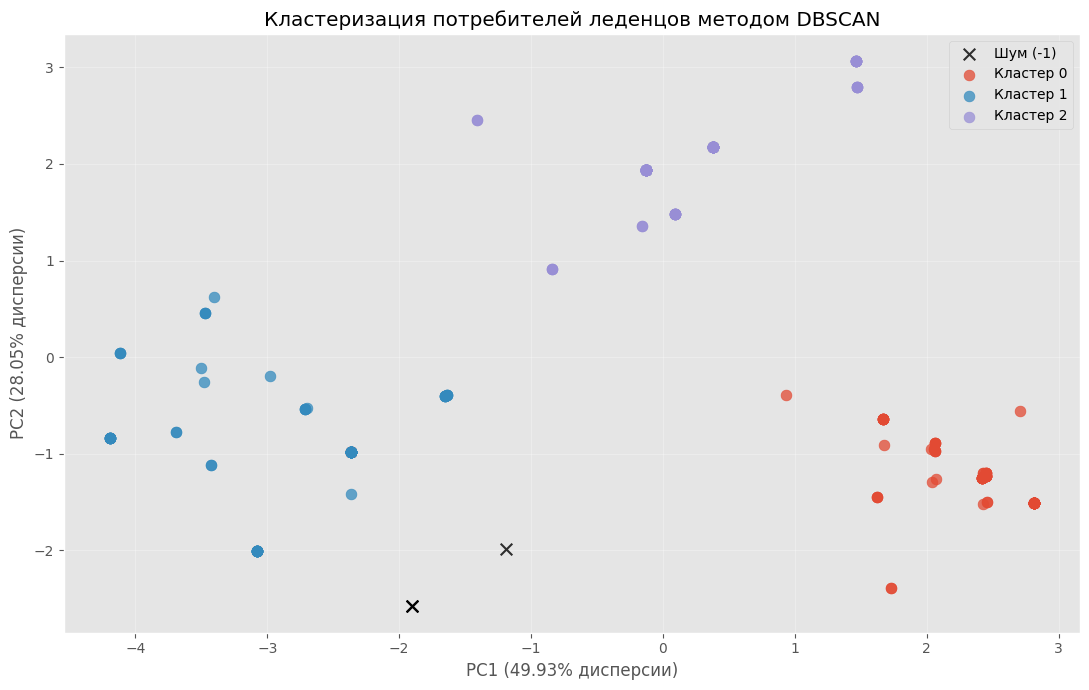

PC1 объясняет 49.93% дисперсии
PC2 объясняет 28.05% дисперсии
Суммарно: 77.98%


In [ ]:
# PCA-визуализация итогового варианта DBSCAN
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
pca_df['Cluster'] = clusters.astype(str)

variance = pca.explained_variance_ratio_ * 100

plt.figure(figsize=(11, 7))

unique_clusters = sorted(pca_df['Cluster'].unique(), key=lambda x: int(x))

for cluster in unique_clusters:
    mask = pca_df['Cluster'] == cluster

    if cluster == '-1':
        plt.scatter(
            pca_df.loc[mask, 'PC1'],
            pca_df.loc[mask, 'PC2'],
            s=70,
            c='black',
            marker='x',
            label='Шум (-1)',
            alpha=0.8
        )
    else:
        plt.scatter(
            pca_df.loc[mask, 'PC1'],
            pca_df.loc[mask, 'PC2'],
            s=60,
            alpha=0.75,
            label=f'Кластер {cluster}'
        )

plt.title('Кластеризация потребителей леденцов методом DBSCAN')
plt.xlabel(f'PC1 ({variance[0]:.2f}% дисперсии)')
plt.ylabel(f'PC2 ({variance[1]:.2f}% дисперсии)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f'PC1 объясняет {variance[0]:.2f}% дисперсии')
print(f'PC2 объясняет {variance[1]:.2f}% дисперсии')
print(f'Суммарно: {variance.sum():.2f}%')

На графике отображены:
- Кластер 0 (красный) — справа внизу.
- Кластер 1 (синий) — слева.
- Кластер 2 (фиолетовый) — сверху.
- Шум (чёрные крестики) — две визуально различимые точки в нижней центральной части.

Также, видно только два чёрных крестика, хотя шумовых объектов четыре. Вероятнее всего, некоторые объекты имеют одинаковые координаты PCA и накладываются друг на друга.

Проанализируем шумовые объекты ниже.

In [ ]:

# Выделяем шумовые наблюдения
noise = X.loc[clusters == -1].copy()

# Сохраняем номера исходных строк
noise.insert(0, 'Номер наблюдения', noise.index + 1)

print("Количество шумовых объектов:", len(noise))

# Показываем исходные значения признаков
display(noise)

# Средние значения признаков для шума
print("\nСредние значения признаков шумовых объектов:")
display(noise.drop(columns='Номер наблюдения').mean().round(2))


Количество шумовых объектов: 4


,Номер наблюдения,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
112,113,2,4,4,4,2,2,2,3,5,5,5
139,140,2,4,4,4,2,2,2,3,5,5,5
177,178,2,4,4,4,2,2,2,3,5,4,4
188,189,2,4,4,4,2,2,2,3,5,5,5



Средние значения признаков шумовых объектов:


,0
V1,2.00
V2,4.00
V3,4.00
V4,4.00
V5,2.00
V6,2.00
V7,2.00
V8,3.00
V9,5.00
V10,4.75


У всех четырёх наблюдений прослеживается необычная комбинация потребностей:
- V1 = 2 — низкая значимость освежения дыхания.
- V2–V4 = 4 — высокая значимость уверенности, свежести полости рта и устранения неприятного вкуса.
- V5–V7 = 2 — слабая выраженность мотивов сладкого вкуса и концентрации.
- V8 = 3 — нейтральная оценка возможности отвлечься.
- V9–V11 = 4–5 — высокая значимость облегчения неприятных симптомов и улучшения самочувствия.

Текущие респонденты, которые попали в шум, одновременно демонстрируют выраженные оздоровительные мотивы и некоторые мотивы, связанные со свежестью полости рта. Это делает их малочисленной группой с разными потребительскими мотивами.



**Вывод:**

В ходе лабораторной работы был проведён иерархический кластерный анализ потребителей леденцов на основе данных опроса 338 респондентов по 11 признакам, характеризующим основные мотивы потребления продукции.

На этапе предварительной обработки были изучены структура данных и описательная статистика. Установлено, что пропущенные значения отсутствуют, а признаки имеют сопоставимые масштабы измерения, поэтому кластеризация проводилась без дополнительной стандартизации.

Для выполнения кластерного анализа был выбран алгоритм DBSCAN с использованием евклидовой метрики расстояния. Основное внимание уделялось обоснованию параметров eps и min_samples, определяющих радиус окрестности и минимальное количество наблюдений, необходимое для формирования области достаточной плотности.

Для предварительного выбора параметров были построены графики расстояний до k-го ближайшего соседа при значениях min_samples=6, 12 и 22. На основании эмпирического правила (D+1), где (D=11) — количество признаков, было выбрано значение min_samples=12. Далее проведено сравнение результатов кластеризации при различных значениях eps с учётом количества кластеров, доли шумовых объектов и содержательной интерпретируемости полученных групп.

При `eps=1.5` алгоритм выделил семь кластеров и 29 шумовых наблюдений (8,58% выборки). При увеличении радиуса до `eps=2.0` количество кластеров сократилось до трёх, а число шумовых объектов — до четырёх (1,18%). На основании сравнительного анализа в качестве итоговых параметров были выбраны `eps=2.0` и `min_samples=12`, обеспечивающие формирование крупных потребительских сегментов при небольшой доле шума.

В результате анализа были выделены три группы потребителей:

Потребители, ориентированные на свежесть (110 человек, 32,54%) — респонденты, употребляющие леденцы преимущественно для освежения дыхания, поддержания свежести полости рта и повышения уверенности.

Оздоровительные потребители (104 человека, 30,77%) — респонденты, для которых основными мотивами являются облегчение боли в горле, устранение заложенности носа и улучшение самочувствия.

Потребители со смешанными мотивами (120 человек, 35,50%) — группа, объединяющая респондентов, ориентированных на сладкий вкус, концентрацию внимания и кратковременный отдых.

Содержательная интерпретация кластеров была выполнена на основании средних значений признаков внутри каждой группы. Для визуализации результатов использовался метод главных компонент (PCA), позволивший снизить размерность исходных данных с 11 до 2 измерений. Первые две главные компоненты объясняют суммарно 77,98% дисперсии. Построенная диаграмма рассеяния наглядно продемонстрировала пространственное расположение выделенных кластеров и шумовых наблюдений.

Отдельно был проведён анализ четырёх шумовых объектов, которым алгоритм присвоил метку `-1`. Установлено, что три наблюдения имеют полностью одинаковые значения признаков, а четвёртое отличается от них только по двум показателям. Для данных респондентов характерно сочетание выраженных оздоровительных мотивов и потребностей, связанных со свежестью полости рта. При выбранных параметрах эти наблюдения не образуют самостоятельную область достаточной плотности и не включаются в существующие кластеры.